In [1]:
import sys
sys.path.append("../")
from generator.generator_synthetic import SyntheticGenerator
import datetime
import matplotlib.pyplot as plt

INFO:albumentations.check_version:A new version of Albumentations is available: 2.0.5 (you have 1.4.13). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.


#### Specify the settings to generate the synthetic image

In [27]:
settings = {
  "0": {
    "save": False,
    "plot_mask": True,
    "train_val_ratio": 0,
    "grid": {
      "type": "continuous carbon",
      "path": None,
      "stepSize": [
        1024
      ],
      "windowSize": [
        [
          1024,
          1024
        ]
      ],
      "Restrict2carbon": False,
      "Restrict2Holes": False
    },
    "particle": "polygon",
    "initial_i_min": 7,
    "initial_i_max": 8,
    "axes_ratio": 1.0,
    "no_of_magnifications": 1,
    "particle_size_min": 349,
    "particle_size_max": 350,
    "generate_cluster": True,
    "cluster_type": "honeycomb",
    "num_rows_min": 2,
    "num_rows_max": 7,
    "num_cols_min": 2,
    "num_cols_max": 7,
    "num_width_min": 100,
    "num_width_max": 101,
    "cluster_random_num": 10,
    "num_of_points": 1,
    "max_overlap": 1.0,
    "vertices_min": 4,
    "vertices_max": 6,
    "irregularity": 0.2,
    "particle_weight": 0.2,
    "particle_noise": {
      "type": "none",
      "frequency": 0.05,
      "octaves": 15,
      "gain": 0.5,
      "lacunarity": 2.0
    },
    "particle_noise_weight": 0.2,
    "gradient_weight": 0.0,
    "illumination_type": "half particle (default)",
    "illumination_weight": 2.0,
    "illumination_kernel": 21,
    "illumination_sigmaX": 2,
    "rescale_intensity": False,
    "rescale_intensity_prob": 1.0,
    "class_name": "particle",
    "image_noise": {
      "type": "simplexfracta",
      "frequency": 0.1,
      "octaves": 5,
      "gain": 0.1,
      "lacunarity": 1.0
    },
    "image_noise_weight": 0.5,
    "invert_image": False
  }}

In [28]:
# Initiate COCO dataset dictionary

data_train = {}
data_val = {}

data_train_coco = {'info':{
                        "description": 'Synthetic data with experimental background',
                        "year": '2024',
                        "contributor": "https://github.com/nataliaasaa",
                        "date_created": str(datetime.datetime.now())
                        },
                'images':[],
                'annotations':[],
                'categories':[
                    {"supercategory": "particle",
                    "id": 1,
                    "name": "particle"}]
                }
data_val_coco = {'info':{
                        "description": 'Synthetic data with experimental background',
                        "year": '2024',
                        "contributor": "https://github.com/nataliaasaa",
                        "date_created": str(datetime.datetime.now())
                        },
                'images':[],
                'annotations':[],
                'categories':[
                    {"supercategory": "particle",
                    "id": 1,
                    "name": "particle"}]
                }

#### Visualise the image generated from one specific setting

In [29]:
count = 0

key_of_interest = '0'
settings[key_of_interest]['plot_mask'] = True

# Create a new dict with only the key of interes
setting_0 = dict()
setting_0['1'] = settings[key_of_interest].copy() 

# Save image from generate synthetic
_, _, _, _, _, final_image, gt_image = SyntheticGenerator().generate_synthetic_data(1, 2048, setting_0, 
                                        count, None, data_train, 
                                        data_val, data_train_coco, 
                                        data_val_coco)

In [30]:
import numpy as np
np.max(final_image)

255.0

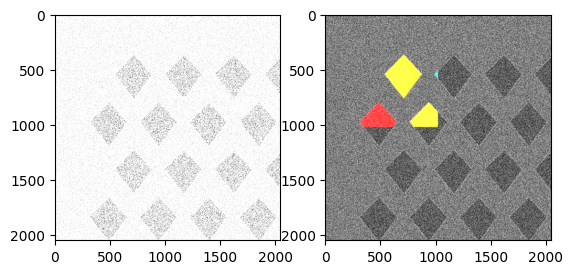

In [33]:
import cv2
figure, (ax1, ax2) = plt.subplots(1, 2)
brighter_img = np.clip(final_image * 3, 0, 255).astype(np.uint8)  # 1.2 is the scaling factor

ax1.imshow(brighter_img, cmap='gray')
ax2.imshow(gt_image)
plt.show()

#### For more than one setting

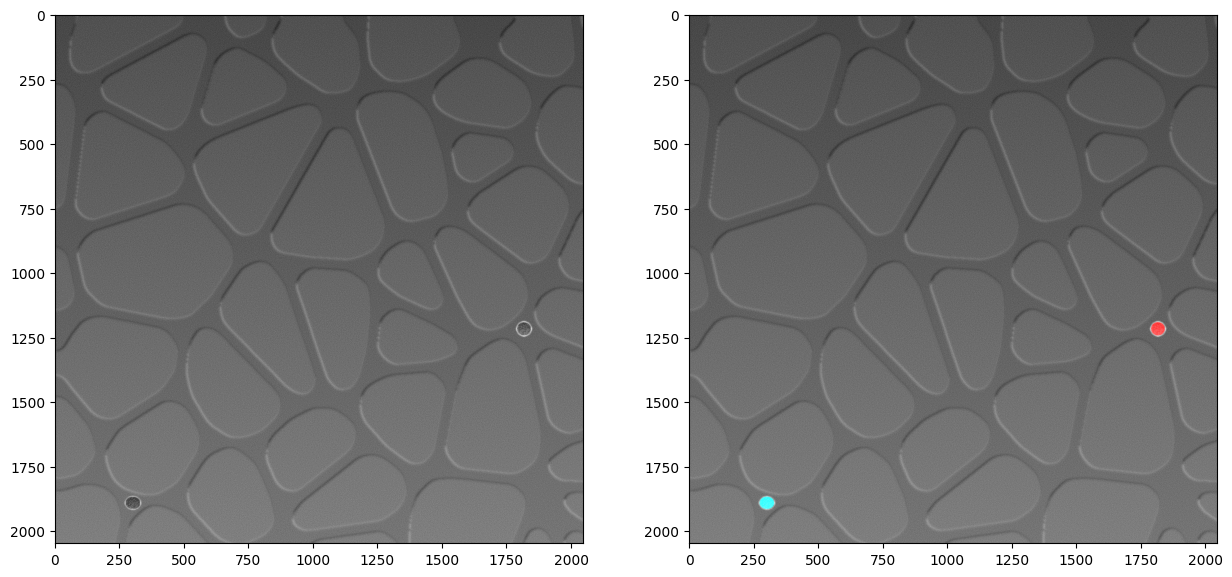

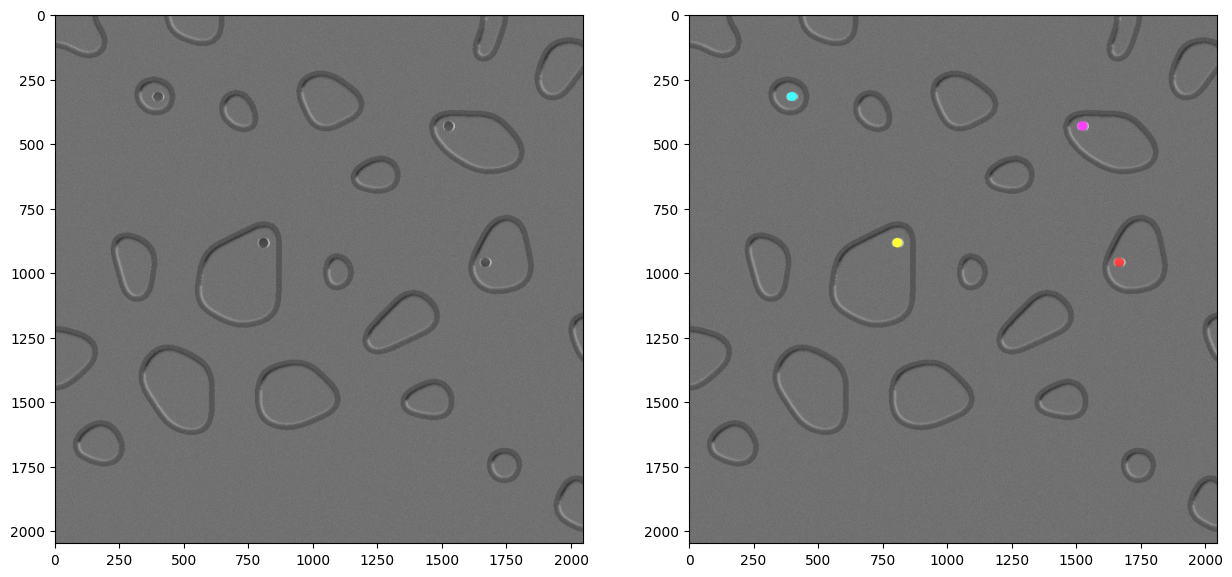

In [6]:
# Plot the settings in loop: send to plot_image one key/value at a time
for key in settings:
    individual_settings = dict()
    individual_settings[key] = settings[key].copy()
    # Activate Plot Mask setting            
    individual_settings[key]['plot_mask'] = True
    _, _, _, _, _, final_image, gt_image = SyntheticGenerator().generate_synthetic_data(1, 2048, individual_settings, 
                                        count, None, data_train, 
                                        data_val, data_train_coco, 
                                        data_val_coco)
    
    figure, (ax1, ax2) = plt.subplots(1, 2,  figsize=(15, 15))
    ax1.imshow(final_image, cmap='gray')
    ax2.imshow(gt_image)
    plt.show()

#### Saving the Dataset

In [7]:
import os
import json

ROOT_DIR = './' # Path to save

path = os.path.join(ROOT_DIR, datetime.datetime.now().strftime("%Y%m%d%H%M%S")) 

os.mkdir(path) 
os.mkdir(path + '/train/')
os.mkdir(path + '/val/')


In [12]:
# Change setting to save=True, otherwise the image will not be saved
for key in settings:
    settings[key]['save']=True
    settings[key]['plot_mask']=False

In [13]:
num_of_images = 10
img_size = 2048
count = 0

data_train, data_val, data_train_coco, data_val_coco, count, _, _ = SyntheticGenerator().generate_synthetic_data(num_of_images, img_size, settings, 
                                                                                                                    count, path, data_train, data_val, 
                                                                                                                    data_train_coco, data_val_coco)

# Save annotations as json
train_json = os.path.join(path + '/train/via_region_data.json')   
val_json = os.path.join(path + '/val/via_region_data.json')   
train_coco = os.path.join(path + '/train/instances_train.json')   
val_coco = os.path.join(path + '/val/instances_val.json')   

# This is VIA (VGG Image Annotator) format for mask rcnn
with open(train_json, "w") as f:
        json.dump(data_train, f, ensure_ascii=False, indent=2)        

with open(val_json, "w") as f:
        json.dump(data_val, f, ensure_ascii=False, indent=2) 

# This is COCO format for detectron2
with open(train_coco, "w") as f:
        json.dump(data_train_coco, f, ensure_ascii=False, indent=2)  

with open(val_coco, "w") as f:
        json.dump(data_val_coco, f, ensure_ascii=False, indent=2)  